# Feature importance: SHAP vs. permutation importance

Per ADR-0004, feature pruning is deferred to evidence from the trained model, not the EDA correlation matrix. `scripts/train_hgb.py` now computes SHAP via a model-agnostic explainer (not `TreeExplainer`, which was found broken for this model's native categorical splits). This notebook is the fast, repeatable check: confirm the logged SHAP output for the current candidate run still agrees with permutation importance. The sample-size sufficiency question itself is answered once, in `03_shap_sample_size_convergence.ipynb` -- not re-investigated here.

In [1]:
RUN_ID = "6d177e7ddd4640769f6a09df8c27870a"  # hgb_candidate_shap-permutation

In [2]:
from pathlib import Path

import json
import mlflow
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sklearn.inspection import permutation_importance

import os

def find_root(start: Path) -> Path:
    p = start.resolve()
    while not (p / "pyproject.toml").exists():
        p = p.parent
    return p

ROOT = find_root(Path.cwd())
load_dotenv(ROOT / ".env")
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000"))

import sys
sys.path.insert(0, str(ROOT / "src"))
from taxi_mlops.config import load_params
from taxi_mlops.features import build_feature_table, feature_columns, split_by_period

params = load_params((ROOT / "params.yaml"))
cols = feature_columns(params)
cols

['lag_1',
 'lag_2',
 'lag_3',
 'lag_24',
 'lag_168',
 'roll_3',
 'roll_24',
 'roll_168',
 'hour_of_day',
 'day_of_week',
 'is_weekend',
 'zone_id']

## Load the logged model and the test split (identical to training)

In [3]:
model = mlflow.sklearn.load_model(f"runs:/{RUN_ID}/model")

zone_ids = [z["zone_id"] for z in json.loads((ROOT / "config" / "selected_zones.json").read_text())]
zone_hour = pd.read_parquet(ROOT / "data" / "processed" / "zone_hour_counts.parquet")
zone_hour = zone_hour[zone_hour.zone_id.isin(zone_ids)]
feature_table = build_feature_table(zone_hour, params)
train = split_by_period(feature_table, params, "train")
test = split_by_period(feature_table, params, "test")
X_test, y_test = test[cols], test["target"]
X_test.shape

(6240, 12)

## SHAP values already logged on this run

Download the artifact rather than recomputing it -- same values the training run produced.

In [4]:
local_dir = mlflow.artifacts.download_artifacts(run_id=RUN_ID, artifact_path="shap")
npz = np.load(Path(local_dir) / "shap_values.npz", allow_pickle=True)
shap_values = npz["shap_values"]
feature_names = list(npz["feature_names"])
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names, name="mean_abs_shap")
mean_abs_shap.sort_values(ascending=False)

lag_1          81.995325
lag_24         40.106137
lag_168        38.284174
hour_of_day    13.864086
lag_3          13.232874
zone_id         7.315092
roll_168        6.412821
day_of_week     6.140766
roll_24         3.249446
lag_2           2.451565
roll_3          1.918126
is_weekend      0.000000
Name: mean_abs_shap, dtype: float64

## Permutation importance

Independent of SHAP's internals entirely -- shuffle one column at a time, remeasure MAE, repeat. Scored on the same test split, same model, so this is a direct cross-check, not a different experiment.

In [5]:
result = permutation_importance(
    model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=params["random_seed"],
)
perm_importance = pd.Series(result.importances_mean, index=cols, name="perm_importance_mae_increase")
perm_std = pd.Series(result.importances_std, index=cols, name="perm_importance_std")
perm_importance.sort_values(ascending=False)

lag_1          82.582320
lag_24         30.929662
lag_168        28.383268
hour_of_day     9.336173
lag_3           5.105067
zone_id         4.848960
day_of_week     4.184514
roll_168        2.030271
lag_2           0.947216
roll_24         0.945872
roll_3          0.614121
is_weekend      0.000000
Name: perm_importance_mae_increase, dtype: float64

## Side-by-side comparison

Both methods, same features, same model, same data. If they agree on `zone_id` contributing ~nothing, that's real; if they disagree, the SHAP computation itself needs a closer look before trusting it for anything else.

In [6]:
comparison = pd.DataFrame({
    "mean_abs_shap": mean_abs_shap,
    "perm_importance_mae_increase": perm_importance,
    "perm_importance_std": perm_std,
}).sort_values("perm_importance_mae_increase", ascending=False)
comparison

,mean_abs_shap,perm_importance_mae_increase,perm_importance_std
lag_1,81.995325,82.582320,1.045604
lag_24,40.106137,30.929662,0.465078
lag_168,38.284174,28.383268,0.495963
hour_of_day,13.864086,9.336173,0.127737
lag_3,13.232874,5.105067,0.186426
zone_id,7.315092,4.848960,0.210371
day_of_week,6.140766,4.184514,0.190837
roll_168,6.412821,2.030271,0.179091
lag_2,2.451565,0.947216,0.059995
roll_24,3.249446,0.945872,0.073802


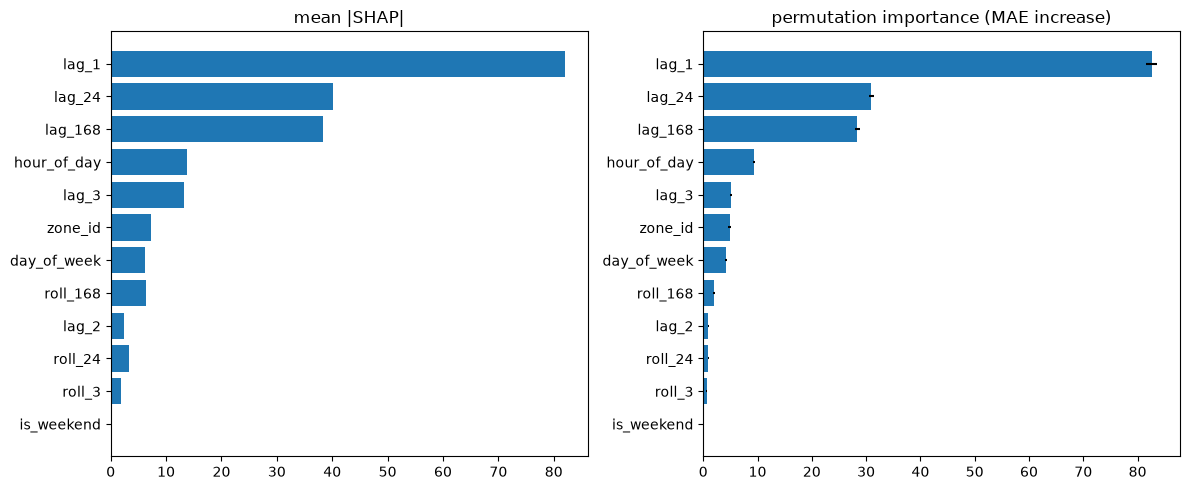

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = comparison.index
axes[0].barh(order, comparison.loc[order, "mean_abs_shap"])
axes[0].set_title("mean |SHAP|")
axes[0].invert_yaxis()
axes[1].barh(order, comparison.loc[order, "perm_importance_mae_increase"],
             xerr=comparison.loc[order, "perm_importance_std"])
axes[1].set_title("permutation importance (MAE increase)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## Root cause, step 1: perturbation assumption

`TreeExplainer`'s default (`tree_path_dependent`) estimates each feature's contribution using the training data's correlation structure along the tree's actual split paths. Permutation importance instead breaks one feature's relationship with the target directly by shuffling it while leaving everything else untouched. Under correlated features these answer genuinely different questions -- so before assuming a bug, try TreeExplainer's other mode (`interventional`), which uses an explicit background sample instead of path-dependent conditioning, and is closer in spirit to what permutation importance does.

In [8]:
background = train[cols].sample(n=200, random_state=params["random_seed"])
explainer_interventional = shap.TreeExplainer(
    model, data=background, feature_perturbation="interventional"
)
shap_values_interventional = explainer_interventional.shap_values(X_test.sample(n=500, random_state=params["random_seed"]))
mean_abs_shap_interventional = pd.Series(
    np.abs(shap_values_interventional).mean(axis=0), index=cols, name="mean_abs_shap_interventional"
).sort_values(ascending=False)
mean_abs_shap_interventional

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


lag_2          0.510284
lag_168        0.192524
roll_3         0.169654
day_of_week    0.084960
lag_24         0.056946
lag_3          0.012250
roll_168       0.007412
roll_24        0.004636
is_weekend     0.004110
lag_1          0.000000
hour_of_day    0.000000
zone_id        0.000000
Name: mean_abs_shap_interventional, dtype: float64

## Root cause, step 2: fully model-agnostic explainer

If `interventional` still disagrees with permutation importance, the disagreement isn't about path-dependence vs. interventional perturbation -- it points at `TreeExplainer`'s handling of this model's native categorical splits specifically. Cross-check with a model-agnostic explainer that only calls `model.predict` and never inspects the tree structure at all, so it cannot be affected by that.

In [9]:
sample_test = X_test.sample(n=100, random_state=params["random_seed"])
masker = shap.maskers.Independent(background, max_samples=200)
agnostic_explainer = shap.explainers.Permutation(model.predict, masker)
agnostic_result = agnostic_explainer(sample_test)
mean_abs_shap_agnostic = pd.Series(
    np.abs(agnostic_result.values).mean(axis=0), index=cols, name="mean_abs_shap_agnostic"
).sort_values(ascending=False)
mean_abs_shap_agnostic

PermutationExplainer explainer:   7%|▋         | 7/100 [00:00<?, ?it/s]

PermutationExplainer explainer:   9%|▉         | 9/100 [00:12<01:53,  1.24s/it]

PermutationExplainer explainer:  10%|█         | 10/100 [00:14<02:08,  1.42s/it]

PermutationExplainer explainer:  11%|█         | 11/100 [00:17<02:51,  1.92s/it]

PermutationExplainer explainer:  12%|█▏        | 12/100 [00:24<05:17,  3.61s/it]

PermutationExplainer explainer:  13%|█▎        | 13/100 [00:25<04:11,  2.89s/it]

... (86 outputs left out)

PermutationExplainer explainer: 100%|██████████| 100/100 [02:19<00:00,  1.80s/it]

PermutationExplainer explainer: 101it [02:19,  1.41s/it]                         

PermutationExplainer explainer: 101it [02:19,  1.49s/it]

lag_1          87.202392
lag_24         41.451427
lag_168        40.000574
hour_of_day    14.525569
lag_3          12.512802
zone_id         7.167771
roll_168        5.892999
day_of_week     5.626820
roll_24         3.111904
lag_2           2.419402
roll_3          1.766442
is_weekend      0.000000
Name: mean_abs_shap_agnostic, dtype: float64

## Full comparison: four signals side by side

In [10]:
full_comparison = pd.DataFrame({
    "shap_tree_path_dependent": mean_abs_shap,
    "shap_tree_interventional": mean_abs_shap_interventional,
    "shap_model_agnostic": mean_abs_shap_agnostic,
    "perm_importance": perm_importance,
}).sort_values("perm_importance", ascending=False)
full_comparison

,shap_tree_path_dependent,shap_tree_interventional,shap_model_agnostic,perm_importance
lag_1,81.995325,0.000000,87.202392,82.582320
lag_24,40.106137,0.056946,41.451427,30.929662
lag_168,38.284174,0.192524,40.000574,28.383268
hour_of_day,13.864086,0.000000,14.525569,9.336173
lag_3,13.232874,0.012250,12.512802,5.105067
zone_id,7.315092,0.000000,7.167771,4.848960
day_of_week,6.140766,0.084960,5.626820,4.184514
roll_168,6.412821,0.007412,5.892999,2.030271
lag_2,2.451565,0.510284,2.419402,0.947216
roll_24,3.249446,0.004636,3.111904,0.945872


## Conclusion

Fill in after running: does `interventional` perturbation (step 1) resolve the disagreement with permutation importance? If yes, this was a perturbation-assumption mismatch, not a bug -- `tree_path_dependent` SHAP simply answers a different question under correlated features. If `interventional` still disagrees but the model-agnostic explainer (step 2) agrees with permutation importance, that implicates `TreeExplainer`'s handling of this model's native categorical splits specifically. Update ADR-0004 with whichever it turns out to be, and only then decide whether zone_id or any lag/rolling feature should actually be dropped.